In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
data = pd.read_csv("ecg.csv")
x = data.iloc[:,:-1].values
y = data.iloc[:,-1].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

x_train = x_train[y_train==0]

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (3997, 140)
Testing data:  (1000, 140)
Training data:  (1663, 140)
Testing data:  (1000, 140)


In [4]:
model = Sequential()

model.add(Dense(64, activation='relu', input_shape=(140,)))
model.add(Dense(32, activation='relu'))

model.add(Dense(64, activation='relu'))
model.add(Dense(140, activation='linear'))

model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = 'mse',
    metrics = ['mae']
)

model.summary()

C:\Users\ayush\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    x_train, x_train,
    epochs = 10,
    batch_size = 256,
    validation_split = 0.2
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 1.0640 - mae: 0.7168 - val_loss: 0.8898 - val_mae: 0.6614
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.9980 - mae: 0.6962 - val_loss: 0.8523 - val_mae: 0.6469
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.9396 - mae: 0.6741 - val_loss: 0.7978 - val_mae: 0.6232
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.8604 - mae: 0.6412 - val_loss: 0.7366 - val_mae: 0.5960
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.7791 - mae: 0.6079 - val_loss: 0.6695 - val_mae: 0.5634
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.6947 - mae: 0.5673 - val_loss: 0.6041 - val_mae: 0.5270
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.6195 - mae: 0.5283 - val_loss: 0.5450 - val_mae: 0.4951
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.5540 - mae: 0.4945 - val_loss: 0.4914 - val_mae: 0.4659
Epoch 9/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.4940 - mae: 0.4621 - 

In [9]:
#train
train_predictions = model.predict(x_train)
train_errors = np.mean(np.square(x_train - train_predictions), axis=1)

threshold = np.mean(train_errors) + 3*np.mean(train_errors)
print("Threshold: ", threshold)

#test
test_predictions = model.predict(x_test)
errors = np.mean(np.square(x_test - test_predictions), axis=1)

y_pred = (errors > threshold).astype(int)

print("Predicted anomalies: ", y_pred[:20])
print("Total anomalies detected: ", np.sum(y_pred))

52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Threshold:  1.6633968057631248
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Predicted anomalies:  [1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0]
Total anomalies detected:  217


In [11]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

[[401  15]
 [382 202]]
              precision    recall  f1-score   support

         0.0       0.51      0.96      0.67       416
         1.0       0.93      0.35      0.50       584

    accuracy                           0.60      1000
   macro avg       0.72      0.65      0.59      1000
weighted avg       0.76      0.60      0.57      1000



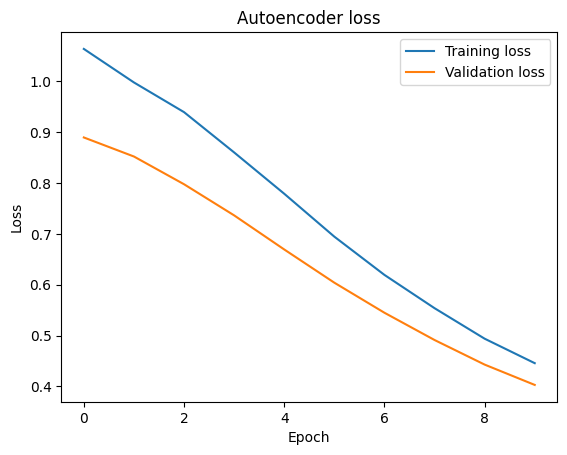

In [12]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Autoencoder loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()